# Brain Tumor MRI Classification — DenseNet201 (20 Epochs)


Found 2144 images belonging to 3 classes.
Found 458 images belonging to 3 classes.
Found 462 images belonging to 3 classes.
Epoch 1/20


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


67/67 - 449s - 7s/step - accuracy: 0.6684 - loss: 0.7627 - val_accuracy: 0.8450 - val_loss: 0.4217
Epoch 2/20
67/67 - 423s - 6s/step - accuracy: 0.8148 - loss: 0.4614 - val_accuracy: 0.8559 - val_loss: 0.3568
Epoch 3/20
67/67 - 422s - 6s/step - accuracy: 0.8377 - loss: 0.4014 - val_accuracy: 0.8668 - val_loss: 0.3206
Epoch 4/20
67/67 - 432s - 6s/step - accuracy: 0.8624 - loss: 0.3539 - val_accuracy: 0.8755 - val_loss: 0.2998
Epoch 5/20
67/67 - 432s - 6s/step - accuracy: 0.8839 - loss: 0.3097 - val_accuracy: 0.8799 - val_loss: 0.2859
Epoch 6/20
67/67 - 428s - 6s/step - accuracy: 0.8913 - loss: 0.2782 - val_accuracy: 0.8952 - val_loss: 0.2784
Epoch 7/20
67/67 - 425s - 6s/step - accuracy: 0.9016 - loss: 0.2714 - val_accuracy: 0.8974 - val_loss: 0.2753
Epoch 8/20
67/67 - 431s - 6s/step - accuracy: 0.9128 - loss: 0.2392 - val_accuracy: 0.8886 - val_loss: 0.2608
Epoch 9/20
67/67 - 442s - 7s/step - accuracy: 0.9184 - loss: 0.2291 - val_accuracy: 0.9017 - val_loss: 0.2562
Epoch 10/20
67/67 - 3

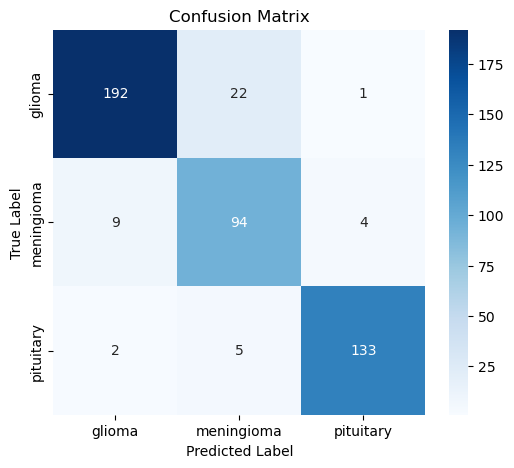

🔢 Precision-Recall AUC for class 2: 0.98


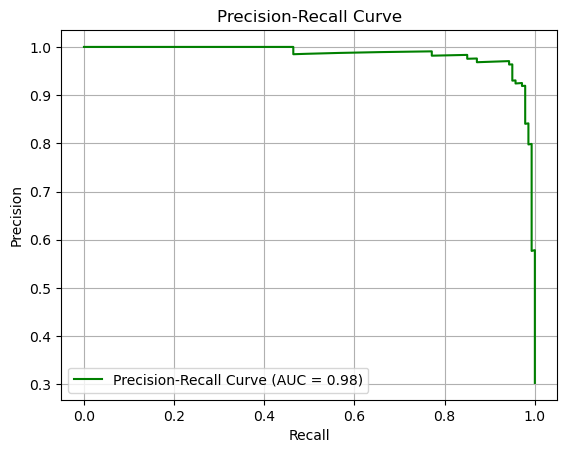

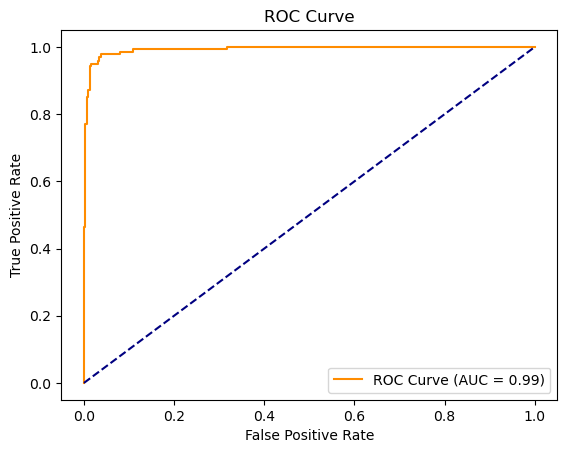

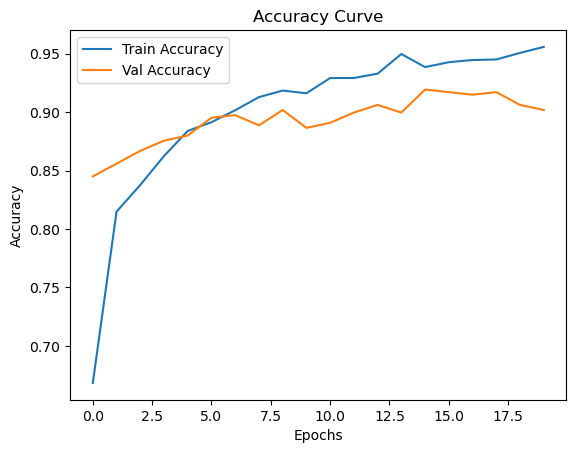

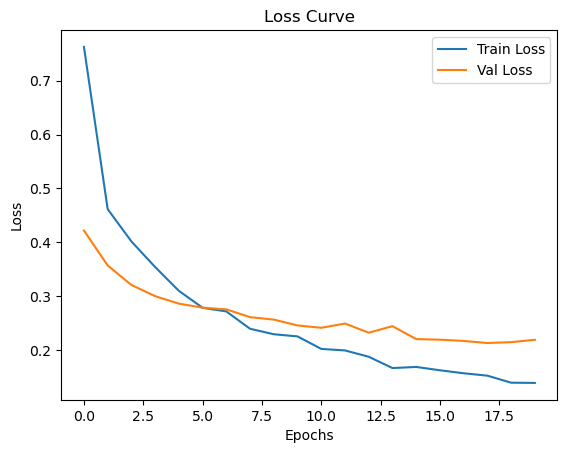

In [1]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.applications import DenseNet201
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve, roc_curve, auc, confusion_matrix, classification_report
import seaborn as sns
import os

# Base data directory
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

# Image parameters
img_height, img_width = 224, 224
batch_size = 32

# ImageDataGenerator
datagen = ImageDataGenerator(rescale=1./255)

train_data = datagen.flow_from_directory(train_dir, target_size=(img_height, img_width),
                                         batch_size=batch_size, class_mode='categorical', shuffle=True)
val_data = datagen.flow_from_directory(val_dir, target_size=(img_height, img_width),
                                       batch_size=batch_size, class_mode='categorical', shuffle=True)
test_data = datagen.flow_from_directory(test_dir, target_size=(img_height, img_width),
                                        batch_size=batch_size, class_mode='categorical', shuffle=False)

# Load DenseNet201 base model
base_model = DenseNet201(weights='imagenet', include_top=False, input_shape=(img_height, img_width, 3))
base_model.trainable = False  # Freeze base model layers

# Add custom top layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(3, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

# Compile model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

# Early stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train model
history = model.fit(train_data, epochs=20, validation_data=val_data, callbacks=[early_stopping], verbose=2)

# Evaluate
test_loss, test_acc = model.evaluate(test_data)
print(f"\n✅ Test Accuracy: {test_acc * 100:.2f}%")
print(f"❌ Test Loss: {test_loss:.4f}")

# Predictions
test_labels = test_data.classes
test_preds = model.predict(test_data)
test_preds_labels = np.argmax(test_preds, axis=1)

# Confusion matrix
conf_matrix = confusion_matrix(test_labels, test_preds_labels)
print("\nConfusion Matrix:")
print(conf_matrix)

print("\nClassification Report:")
print(classification_report(test_labels, test_preds_labels, target_names=test_data.class_indices.keys()))

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_data.class_indices.keys(),
            yticklabels=test_data.class_indices.keys())
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Precision-Recall Curve (for class index 2)
precision, recall, _ = precision_recall_curve(test_labels == 2, test_preds[:, 2])
pr_auc = auc(recall, precision)
print(f"🔢 Precision-Recall AUC for class 2: {pr_auc:.2f}")

plt.figure()
plt.plot(recall, precision, label=f'Precision-Recall Curve (AUC = {pr_auc:.2f})', color='green')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.show()

# ROC Curve (for class index 2)
fpr, tpr, _ = roc_curve(test_labels == 2, test_preds[:, 2])
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})', color='darkorange')
plt.plot([0, 1], [0, 1], linestyle='--', color='navy')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Accuracy & Loss curves
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [2]:
model.save('DenseNet201 model_20 Epochs.h5')  # Save the model
print("Model saved successfully!")

Model saved successfully!


In [1]:
import time
import os
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# === PATHS ===
model_path = r"C:\Users\usER\Downloads\DenseNet201 model_20 Epochs.h5"
image_path = r"C:\Users\usER\Downloads\1512427\converted_images_split\test\glioma\3061.jpg"

# === Load Model ===
model = load_model(model_path)
print("✅ Model loaded successfully.")

# === Load and Preprocess Image ===
img = load_img(image_path, target_size=(224, 224))  # adjust to your model input
img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)  # shape: (1, 224, 224, 3)

# === Measure Inference Time ===
start = time.time()
_ = model.predict(img_array)
end = time.time()

inference_time_ms = (end - start) * 1000
print(f"🕒 Inference Time: {inference_time_ms:.2f} ms")

# === Measure Model Size ===
model_size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"💾 Model Size: {model_size_mb:.2f} MB")


✅ Model loaded successfully.
1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step
🕒 Inference Time: 12558.76 ms
💾 Model Size: 83.25 MB


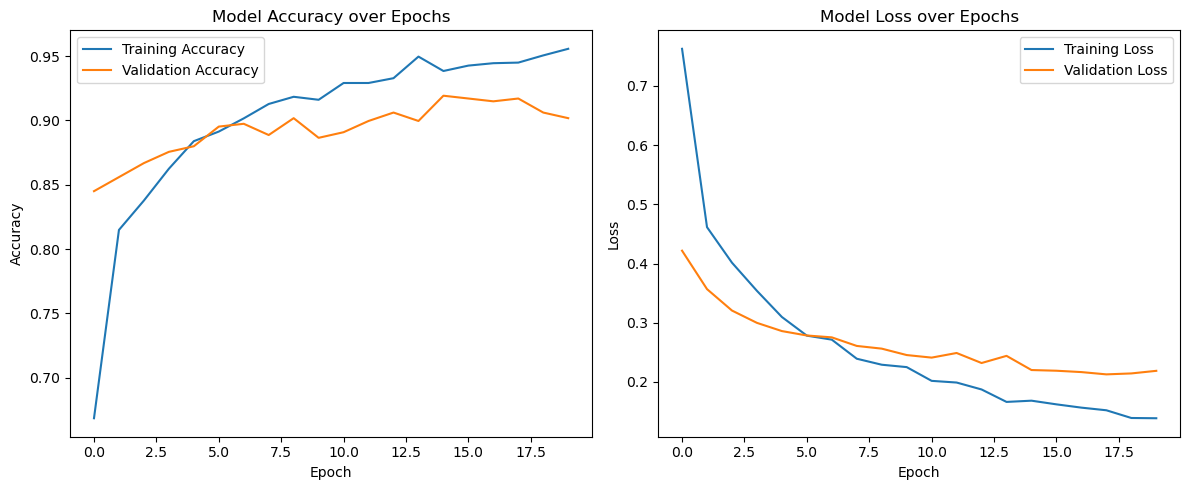

In [3]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot training & validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()



Found 462 images belonging to 3 classes.


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


15/15 ━━━━━━━━━━━━━━━━━━━━ 79s 5s/step

Classification Report:
              precision    recall  f1-score   support

      glioma       0.95      0.89      0.92       215
  meningioma       0.78      0.88      0.82       107
   pituitary       0.96      0.95      0.96       140

    accuracy                           0.91       462
   macro avg       0.90      0.91      0.90       462
weighted avg       0.91      0.91      0.91       462



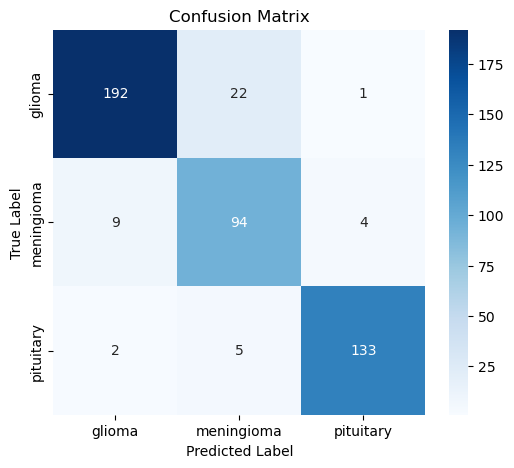

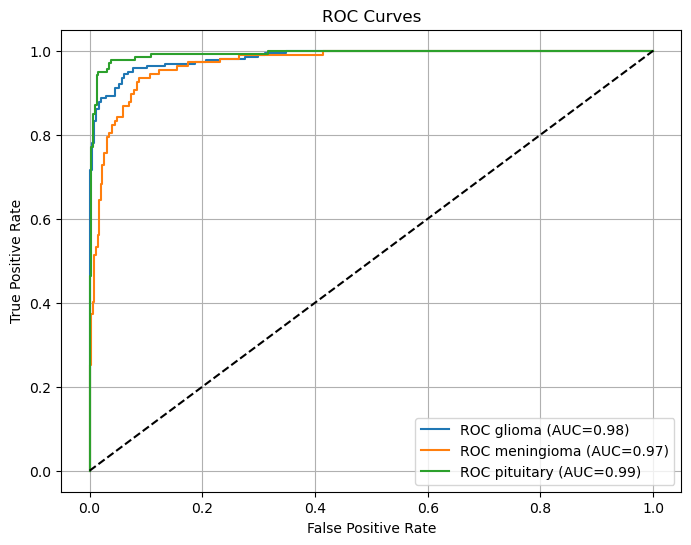

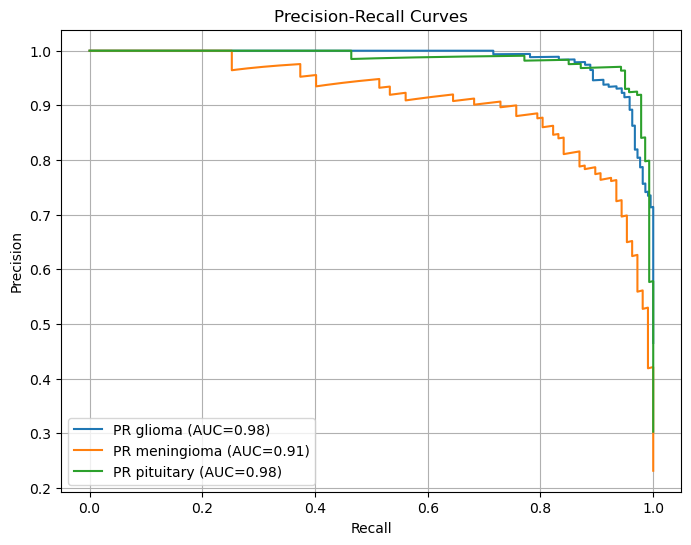

In [4]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load model
model = load_model('DenseNet201 model_20 Epochs.h5')

# Data setup
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'
test_dir = os.path.join(base_dir, 'test')
img_height, img_width = 224, 224
batch_size = 32

datagen = ImageDataGenerator(rescale=1./255)
test_data = datagen.flow_from_directory(test_dir, target_size=(img_height, img_width),
                                        batch_size=batch_size, class_mode='categorical', shuffle=False)

test_labels = test_data.classes
class_names = list(test_data.class_indices.keys())
n_classes = len(class_names)

# Predictions
test_preds = model.predict(test_data)
test_preds_labels = np.argmax(test_preds, axis=1)

# Confusion matrix & report (optional)
from sklearn.metrics import confusion_matrix, classification_report
conf_matrix = confusion_matrix(test_labels, test_preds_labels)
print("\nClassification Report:")
print(classification_report(test_labels, test_preds_labels, target_names=class_names))

# Plot Confusion Matrix (optional)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Binarize labels for multi-class metrics
y_true_bin = label_binarize(test_labels, classes=range(n_classes))

# ROC Curve and AUC per class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], test_preds[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'ROC {class_names[i]} (AUC={roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Precision-Recall Curve and AUC per class
precision = dict()
recall = dict()
pr_auc = dict()
for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], test_preds[:, i])
    pr_auc[i] = auc(recall[i], precision[i])

plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(recall[i], precision[i], label=f'PR {class_names[i]} (AUC={pr_auc[i]:.2f})')
plt.title('Precision-Recall Curves')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()



In [1]:
import numpy as np

# ============================================================
# Confusion Matrix
# Rows    = Actual classes
# Columns = Predicted classes
#
# 0 = Glioma
# 1 = Meningioma
# 2 = Pituitary
# ============================================================

cm = np.array([
    [192, 22, 1],
    [9,  94, 4],
    [2,   5, 133]
])

class_names = ["Glioma", "Meningioma", "Pituitary"]

# Total number of samples
total = np.sum(cm)

sensitivity = []
specificity = []

print("=" * 60)
print("SENSITIVITY AND SPECIFICITY")
print("=" * 60)

for i, class_name in enumerate(class_names):

    # True Positive
    TP = cm[i, i]

    # False Negative
    FN = np.sum(cm[i, :]) - TP

    # False Positive
    FP = np.sum(cm[:, i]) - TP

    # True Negative
    TN = total - (TP + FN + FP)

    # Sensitivity / Recall
    sens = TP / (TP + FN)

    # Specificity
    spec = TN / (TN + FP)

    sensitivity.append(sens)
    specificity.append(spec)

    print(f"\n{class_name}")
    print("-" * 30)
    print(f"TP = {TP}")
    print(f"FN = {FN}")
    print(f"FP = {FP}")
    print(f"TN = {TN}")
    print(f"Sensitivity = {sens:.4f} ({sens * 100:.2f}%)")
    print(f"Specificity = {spec:.4f} ({spec * 100:.2f}%)")


# ============================================================
# Macro Average
# ============================================================

macro_sensitivity = np.mean(sensitivity)
macro_specificity = np.mean(specificity)

print("\n" + "=" * 60)
print("MACRO AVERAGE")
print("=" * 60)

print(
    f"Sensitivity = {macro_sensitivity:.4f} "
    f"({macro_sensitivity * 100:.2f}%)"
)

print(
    f"Specificity = {macro_specificity:.4f} "
    f"({macro_specificity * 100:.2f}%)"
)

print("\n" + "=" * 60)

SENSITIVITY AND SPECIFICITY

Glioma
------------------------------
TP = 192
FN = 23
FP = 11
TN = 236
Sensitivity = 0.8930 (89.30%)
Specificity = 0.9555 (95.55%)

Meningioma
------------------------------
TP = 94
FN = 13
FP = 27
TN = 328
Sensitivity = 0.8785 (87.85%)
Specificity = 0.9239 (92.39%)

Pituitary
------------------------------
TP = 133
FN = 7
FP = 5
TN = 317
Sensitivity = 0.9500 (95.00%)
Specificity = 0.9845 (98.45%)

MACRO AVERAGE
Sensitivity = 0.9072 (90.72%)
Specificity = 0.9546 (95.46%)

